# Semana 13 — EC2 e Kubernetes na AWS com Super Mario
## Aula prática: imagem pública do Docker Hub

Nesta aula vamos executar a imagem `sevenajay/mario:latest` em uma instância EC2 e em um cluster Amazon EKS. O contêiner disponibiliza uma aplicação web; a porta interna usada pela imagem pode variar conforme a publicação. Na EC2, confirme a porta documentada pelo Docker Hub antes de mapear a porta 80. No EKS, o manifesto de exemplo usa porta 80 como destino; ajuste `target-port` se a imagem expuser outra porta.


## Objetivos

- localizar VPC, sub-redes, rotas, Security Groups e EC2 no Console AWS;
- baixar e executar `sevenajay/mario:latest`;
- comparar EC2 (IaaS) com Kubernetes gerenciado (EKS);
- compreender IAM, cluster, plano de controle, grupo de nós e CloudShell;
- publicar a aplicação e encerrar recursos de laboratório.


## Mapa da prática

```text
Navegador --HTTP--> aplicação Mario em contêiner
EC2: VM + Docker + Security Group
EKS: plano de controle + grupo de nós EC2 + Deployment + Pods + Service LoadBalancer
```

No EKS, o Deployment mantém os Pods desejados e o Service encaminha tráfego até os Pods. O Load Balancer cria um ponto de acesso externo; ele pode gerar custos.


## 1. Preparação e custo

1. Inicie o AWS Academy Learner Lab e abra o Console.
2. Confirme a região da turma e use a mesma região em todos os recursos.
3. Verifique com o professor se EKS, CloudShell e as permissões IAM estão habilitados.
4. Anote o saldo/crédito. EKS, nós e Load Balancers podem gerar custos enquanto ativos.

Se o Learner Lab bloquear EKS, conclua a prática de EC2 e faça a comparação guiada. Não tente contornar permissões do laboratório.

## 2. Reconhecer a infraestrutura no Console

Em VPC > Your VPCs, Subnets e Route tables, identifique a VPC, as sub-redes e a rota pública para o Internet Gateway. Em EC2 > Instances, observe a instância da aula e anote:

| Campo | O que observar |
|---|---|
| Instance state / type | estado e tamanho da VM |
| AMI | sistema operacional |
| VPC / Subnet | rede e segmento |
| Private IPv4 / Public IPv4 | endereços e exposição |
| Security groups | portas e origens permitidas |
| Storage | volume EBS |

Na arquitetura em duas camadas, o frontend fica em subnet pública com TCP/80. O backend fica em subnet privada, sem IP público, e recebe TCP/3001 somente do Security Group do frontend. Para HTTPS/443, use ALB e certificado ACM como extensão.

## 3. IaaS: executar a imagem na EC2

Use uma instância pequena permitida pelo Learner Lab. Autorize TCP/80 no Security Group apenas para a origem necessária à aula e restrinja a administração ao método/IP autorizado pelo laboratório. Instale Docker:

```bash
sudo dnf install -y docker
sudo systemctl enable --now docker
```

Consulte no Docker Hub a porta exposta pela imagem. Se for 80, execute:

```bash
sudo docker pull sevenajay/mario:latest
sudo docker run -d --name mario --restart unless-stopped -p 80:80 sevenajay/mario:latest
sudo docker ps
```

Acesse `http://IP_PUBLICO_EC2`. Se a imagem usar outra porta interna, troque o segundo `80` em `-p 80:80` por essa porta; a primeira porta é a publicada na EC2.


## 4. Comparação: EC2 (IaaS) e EKS (Kubernetes gerenciado)

| Aspecto | EC2 com Docker | Amazon EKS |
|---|---|---|
| Host | equipe administra as VMs | AWS administra o plano de controle; nós são configurados à parte |
| Execução | Docker inicia cada container | Deployment agenda e mantém Pods |
| Rede externa | IP, subnet e Security Group | Service LoadBalancer |
| Rede interna | IP privado e Security Group de origem | Service ClusterIP e DNS do cluster |
| Imagens | Docker Hub | Docker Hub |

EKS é um serviço Kubernetes gerenciado (CaaS, frequentemente ensinado junto a PaaS). A equipe ainda administra aplicação, identidade, rede, capacidade e custos.

## Antes da seção 5 — Entendendo Kubernetes com a analogia de um shopping de contêineres

Imagine um **shopping formado por lojas instaladas em contêineres comerciais**. Os clientes procuram a loja Mario; uma recepção distribui as solicitações entre unidades disponíveis. A administração organiza onde cada loja funciona e verifica se as unidades continuam operando. Essa analogia ajuda a entender como o Kubernetes executa e coordena aplicações.

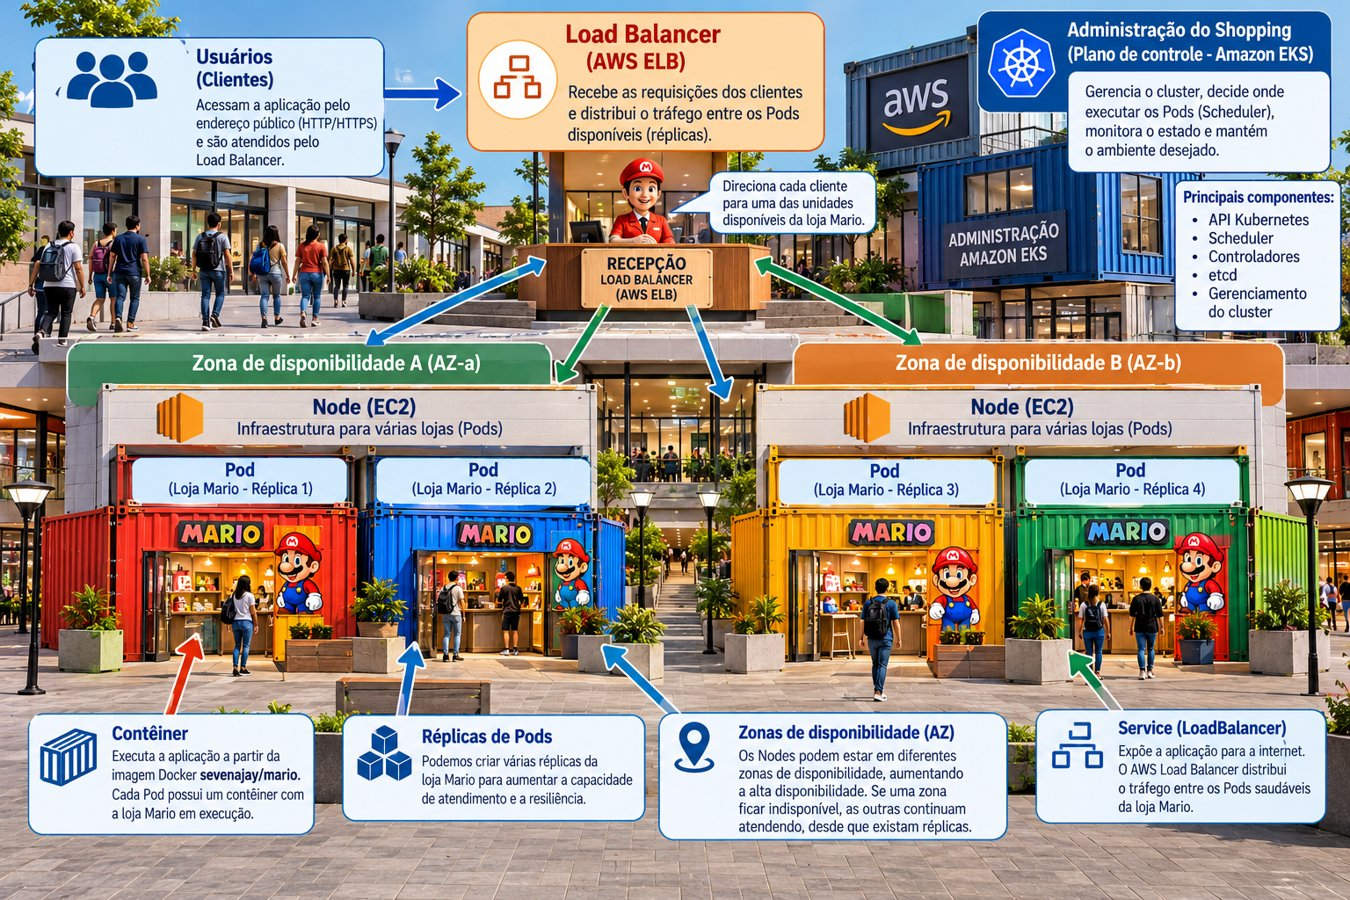

### Quem é quem no shopping?

| Shopping de contêineres | Kubernetes / AWS | Função |
|---|---|---|
| Shopping inteiro | **Cluster Kubernetes (EKS)** | Ambiente que coordena a aplicação |
| Administração central | **Plano de controle EKS** | Mantém o estado desejado do cluster |
| Responsável por alocar espaços | **Scheduler** | Escolhe em qual Node executar cada novo Pod |
| Prédio independente | **Zona de disponibilidade (AZ)** | Local de infraestrutura separado dentro de uma região |
| Bloco comercial com recursos de infraestrutura | **Node (EC2)** | Máquina que fornece CPU, memória e rede para vários Pods |
| Espaço reservado para uma unidade | **Pod** | Unidade de execução que abriga um ou mais contêineres |
| Loja Mario instalada no espaço | **Contêiner** | Processo que executa a aplicação Mario |
| Projeto padronizado da loja | **Imagem `sevenajay/mario`** | Modelo usado para iniciar contêineres equivalentes |
| Quatro unidades Mario | **Deployment com 4 réplicas** | Mantém quatro Pods desejados da aplicação |
| Recepção que encaminha clientes | **AWS Load Balancer** | Distribui requisições entre destinos saudáveis |
| Entrada pública e roteamento estável | **Service `LoadBalancer`** | Expõe a aplicação e integra o balanceador externo |

### Fluxo de atendimento

```text
Cliente (navegador)
   → endereço público do AWS Load Balancer
   → Service Kubernetes (tipo LoadBalancer)
   → um Pod Mario pronto para atender
   → contêiner iniciado da imagem sevenajay/mario
```

A **administração EKS não atende diretamente às requisições HTTP dos clientes**: o plano de controle organiza os Pods, enquanto o Load Balancer encaminha o tráfego da aplicação. O Service representa a abstração de acesso aos Pods; o encaminhamento físico pode envolver NodePort, nós EC2 e regras de rede, conforme o balanceador configurado.

### Réplicas, Nodes e zonas de disponibilidade

Na ilustração, existem **quatro unidades Mario (quatro Pods)**: duas em um Node EC2 na AZ-a e duas em outro Node EC2 na AZ-b. Essa distribuição é **um exemplo didático, não uma garantia automática**. Definir `replicas: 4` solicita quatro Pods, mas não obriga o Kubernetes a distribuí-los igualmente entre nós ou AZs. Para controlar a dispersão, podem ser usadas regras como `topologySpreadConstraints` ou `podAntiAffinity`, desde que exista capacidade nas zonas desejadas.

- **Réplicas**: várias unidades da mesma loja atendem mais solicitações e reduzem o impacto da falha de um Pod.
- **Nodes EC2**: cada bloco tem capacidade limitada; um mesmo Node pode hospedar vários Pods.
- **Zonas de disponibilidade**: prédios independentes reduzem a dependência de um único local. Para resistir à falha de uma AZ, é necessário ter capacidade e Pods saudáveis em outra.
- **CDN (por exemplo, CloudFront)**: funciona como pontos de entrega de conteúdo próximos aos clientes, especialmente para arquivos estáticos em cache. Pode ficar à frente do Load Balancer, mas **não substitui réplicas, Nodes ou AZs**.

> **Limite da analogia:** um Pod não é apenas uma vaga física. Ele também fornece um contexto compartilhado de rede e armazenamento para seus contêineres. Da mesma forma, o Load Balancer distribui **requisições**, não pessoas reais; e o Scheduler decide a localização dos Pods, não o recepcionista.

**Experimento depois da configuração do CloudShell na seção 5.1:**

```bash
kubectl get deployments
kubectl get pods -o wide
kubectl get nodes -L topology.kubernetes.io/zone
kubectl scale deployment mario --replicas=4
kubectl get pods -o wide
```

O comando `scale` modifica a quantidade desejada de Pods. Observe em quais Nodes eles aparecem; **a quantidade de réplicas não demonstra, sozinha, distribuição entre AZs**. A atividade da seção 5 começa com duas réplicas, e o aumento para quatro é um experimento posterior.

**Pergunta para discussão:** se as quatro unidades Mario estiverem no mesmo Node EC2, o que acontece quando ele falha? E se estiverem em Nodes diferentes, mas todos na mesma AZ?


## 5. Implantar no Amazon EKS (se habilitado)

### 5.1 Criar cluster e capacidade no Learner Lab

O Amazon EKS gerencia o **plano de controle** do Kubernetes. Os **nós EC2** executam os Pods e, neste exercício, serão organizados em um **Managed Node Group**. O cluster e o grupo de nós são recursos distintos: um cluster `Active` pode ainda não possuir nenhum nó `Ready`.

**Preparação:** inicie o AWS Academy Learner Lab, abra o Console e escolha a região `us-east-1` (Norte da Virgínia), ou a região indicada pelo professor. Use a mesma região no EKS e no CloudShell. Confirme os créditos disponíveis: EKS, EC2, volumes e Load Balancers podem gerar custos enquanto estiverem ativos.

**IAM no Learner Lab:** antes de criar qualquer role, abra **IAM > Roles** e procure as roles predefinidas com nomes contendo `LabEksClusterRole` e `LabEksNodeRole`. Os nomes completos podem variar de uma sessão para outra. A primeira é assumida pelo serviço `eks.amazonaws.com`; a segunda, pelas instâncias `ec2.amazonaws.com`. A `LabRole` genérica não deve ser escolhida automaticamente só porque possui políticas EKS: verifique a finalidade e a autorização de cada role. **Não modifique políticas IAM para contornar restrições do laboratório.**

**Criação do cluster:**

1. Acesse **Amazon EKS > Clusters > Create cluster** e escolha **Configuração personalizada** (*Custom configuration*).
2. Informe o nome `aula-k8s` e selecione uma versão do Kubernetes disponível e compatível com o laboratório. A versão exibida no Console pode mudar.
3. **Desative o EKS Auto Mode** para usar o fluxo tradicional de Managed Node Groups. O modo automático exige configurações e permissões adicionais. Um aviso sobre `AmazonEKSBlockStoragePolicyV2` na configuração rápida refere-se ao Auto Mode; não anexe essa política apenas para eliminar o aviso.
4. Selecione a role predefinida **`LabEksClusterRole`** (identifique-a pelo trecho do nome). Se não estiver disponível ou não for aceita, registre o erro.
5. Escolha a **VPC autorizada** e ao menos **duas sub-redes em zonas de disponibilidade diferentes**. No laboratório observado, foi utilizada a VPC padrão; os identificadores variam conforme a conta. Verifique acesso ao endpoint e regras de rede. Para uma aula com acesso via CloudShell, o endpoint público pode ser necessário, conforme a conectividade do ambiente; restrinja o acesso quando possível.
6. Mantenha o acesso administrativo do criador do cluster, quando permitido. Revise a configuração, os custos e clique em **Create**. Aguarde o cluster ficar **Active**.

**Criação da capacidade EC2:**

7. Abra **EKS > Clusters > aula-k8s > Compute > Add node group**.
8. Nomeie o grupo `aula-k8s-nodegroup` e selecione a role predefinida **`LabEksNodeRole`**. Não confunda essa role com a role do plano de controle.
9. Escolha capacidade **On-Demand**, instâncias autorizadas pelo Learner Lab (por exemplo, `t3.medium`, se disponível) e AMI compatível. Para demonstrar réplicas, configure **desired = 2**, **min = 1** e **max = 2**, desde que haja créditos e cotas suficientes. Escolha sub-redes permitidas em zonas distintas.
10. Crie o grupo. Aguarde o estado **Active** e confirme que os nós aparecem como **Ready**. Se aparecer `CREATE_FAILED`, consulte os problemas de integridade do grupo antes de tentar novamente.

**CloudShell e kubectl:** abra o CloudShell na região do cluster e execute:

```bash
aws sts get-caller-identity
aws eks update-kubeconfig \
  --region us-east-1 \
  --name aula-k8s
kubectl config current-context
kubectl get nodes -o wide
```

`update-kubeconfig` grava o endpoint e o contexto do cluster no arquivo de configuração do `kubectl`; **não cria o cluster nem concede acesso IAM**. Se `kubectl` tentar `localhost:8080`, geralmente falta configurar o contexto correto. Se houver `Unauthorized` ou `Forbidden`, confira a identidade ativa e as entradas de acesso do EKS. Se os nós não estiverem `Ready`, verifique o grupo, as roles, as sub-redes e a conectividade.

**Verificação opcional do grupo:**

```bash
aws eks describe-nodegroup \
  --cluster-name aula-k8s \
  --nodegroup-name aula-k8s-nodegroup \
  --region us-east-1 \
  --query 'nodegroup.{Status:status,Health:health.issues,Scaling:scalingConfig}'
```

Se a criação de roles, cluster ou nós for negada, registre a mensagem e siga a alternativa da seção 8, sem tentar contornar bloqueios de IAM.

### 5.1.1 Réplicas, zonas de disponibilidade e CDN: qual é a relação?

São três conceitos **complementares, mas diferentes**:

| Conceito | O que replica ou distribui? | Principal objetivo | Exemplo nesta aula |
|---|---|---|---|
| **Réplicas Kubernetes** | Instâncias de Pods da aplicação | Disponibilidade e capacidade de atendimento | `replicas=2` mantém dois Pods Mario desejados |
| **Zonas de disponibilidade (AZs)** | Infraestrutura física isolada dentro de uma região AWS | Resiliência contra falha de uma zona | Nós EC2 em `us-east-1a` e `us-east-1b` |
| **CDN (ex.: CloudFront)** | Cópias em cache de conteúdo em pontos de presença distribuídos geograficamente | Menor latência e menor carga na origem | Arquivos estáticos do jogo entregues por uma CDN |

**Relação entre réplicas e AZs:** ter dois Pods não garante que eles estejam em duas AZs: ambos podem ficar no mesmo nó ou na mesma zona. Para aumentar a resiliência, distribua nós entre AZs e use regras de agendamento como `topologySpreadConstraints` ou `podAntiAffinity`, verificando se há capacidade suficiente. Com apenas dois nós, a distribuição deve ser **observada**, não presumida.

**Relação com CDN:** a CDN **não substitui** réplicas nem zonas de disponibilidade. Ela pode servir arquivos estáticos (HTML, CSS, JavaScript e imagens) a partir de caches próximos dos usuários; requisições dinâmicas e conteúdo não armazenado em cache continuam dependendo da origem. Nesta aula, o Service `LoadBalancer` publica a aplicação, mas **não configura automaticamente o CloudFront**.

```text
Sem CDN:
Navegador -> Load Balancer -> Service -> Pods (em nós EC2/AZs)

Com CDN (arquitetura opcional, não implementada nesta prática):
Navegador -> CloudFront -> cache (quando disponível)
                         -> origem/Load Balancer -> Service -> Pods (quando necessário)
```

**Experimento didático:**

```bash
kubectl get pods -o wide
kubectl get nodes -L topology.kubernetes.io/zone
kubectl scale deployment mario --replicas=3
kubectl get pods -o wide
kubectl scale deployment mario --replicas=2
```

Observe a coluna `NODE` e as zonas de cada nó. Escalar de duas para três réplicas **não cria automaticamente uma terceira instância EC2**; o agendador usa a capacidade disponível e pode deixar Pods pendentes. Se o laboratório estiver com poucos créditos, apenas discuta os comandos sem executá-los.



### 5.2 Deploy da imagem e Service

No CloudShell já configurado, crie um Deployment com dois Pods da imagem Mario. O exemplo supõe que o contêiner atende na porta 80; confira a página da imagem no Docker Hub e ajuste a porta se necessário.

```bash
kubectl create deployment mario --image=sevenajay/mario:latest --replicas=2
kubectl rollout status deployment/mario
kubectl get deployments,pods -o wide
```

Publique a aplicação usando um Service do tipo LoadBalancer:

```bash
kubectl expose deployment mario --type=LoadBalancer --port=80 --target-port=80
kubectl get services --watch
```

Quando aparecer um endereço externo, abra `http://ENDERECO_DO_SERVICE`. O Load Balancer e os nós podem gerar custos. Remova os recursos ao terminar.


#### 5.2.1 Corrigir LoadBalancer público no AWS EKS

```bash
#!/bin/bash

set -e

CLUSTER="aula-k8s"

echo "=== Identificando VPC do EKS ==="

VPC=$(aws eks describe-cluster \
  --name "$CLUSTER" \
  --query "cluster.resourcesVpcConfig.vpcId" \
  --output text)

echo "VPC: $VPC"

echo "=== Localizando subnets ==="

SUBNETS=$(aws eks describe-cluster \
  --name "$CLUSTER" \
  --query "cluster.resourcesVpcConfig.subnetIds[]" \
  --output text)

for SUBNET in $SUBNETS; do

  echo ""
  echo "Verificando subnet: $SUBNET"

  AVAILABLE=$(aws ec2 describe-subnets \
    --subnet-ids "$SUBNET" \
    --query "Subnets[0].AvailableIpAddressCount" \
    --output text)

  ROUTE_TABLE=$(aws ec2 describe-route-tables \
    --filters "Name=association.subnet-id,Values=$SUBNET" \
    --query "RouteTables[0].Routes[?DestinationCidrBlock=='0.0.0.0/0'].GatewayId | [0]" \
    --output text)

  if [ "$ROUTE_TABLE" = "None" ]; then
    ROUTE_TABLE=$(aws ec2 describe-route-tables \
      --filters "Name=vpc-id,Values=$VPC" \
      --query "RouteTables[?Associations[?Main==\`true\`]].Routes[?DestinationCidrBlock=='0.0.0.0/0'].GatewayId | [0][0]" \
      --output text)
  fi

  echo "IPs disponíveis: $AVAILABLE"
  echo "Gateway: $ROUTE_TABLE"

  if [[ "$ROUTE_TABLE" == igw-* ]] && [ "$AVAILABLE" -gt 5 ]; then

    echo "Subnet pública encontrada: $SUBNET"

    aws ec2 create-tags \
      --resources "$SUBNET" \
      --tags \
      Key=kubernetes.io/role/elb,Value=1 \
      Key=kubernetes.io/cluster/$CLUSTER,Value=shared

    echo "Tags aplicadas!"

  else
    echo "Subnet ignorada: não identificada como pública ou sem IPs suficientes."
  fi

done

echo ""
echo "=== Verificando LoadBalancer ==="

kubectl annotate svc mario \
  service.beta.kubernetes.io/aws-load-balancer-scheme=internet-facing \
  --overwrite

kubectl get svc mario -w
```

##### Resultado esperado

```text
NAME    TYPE           CLUSTER-IP      EXTERNAL-IP
mario   LoadBalancer   10.100.215.4   xxxxx.elb.amazonaws.com
```

#### 5.2.2 Exclusão do Cluster


```bash
#!/bin/bash

set -Eeuo pipefail

CLUSTER="aula-k8s"
REGION="us-east-1"

echo "======================================"
echo " DESTROY EKS: $CLUSTER"
echo " REGION: $REGION"
echo "======================================"

# Verificar existência do cluster
if ! aws eks describe-cluster \
    --name "$CLUSTER" \
    --region "$REGION" >/dev/null 2>&1; then
    echo "Cluster não encontrado ou já removido."
    exit 0
fi

# 1. Excluir Fargate Profiles
echo "[1/4] Removendo Fargate Profiles..."

PROFILES=$(aws eks list-fargate-profiles \
    --cluster-name "$CLUSTER" \
    --region "$REGION" \
    --query 'fargateProfileNames[]' \
    --output text)

for PROFILE in $PROFILES; do
    [[ "$PROFILE" == "None" ]] && continue

    aws eks delete-fargate-profile \
        --cluster-name "$CLUSTER" \
        --fargate-profile-name "$PROFILE" \
        --region "$REGION"

    aws eks wait fargate-profile-deleted \
        --cluster-name "$CLUSTER" \
        --fargate-profile-name "$PROFILE" \
        --region "$REGION"
done

# 2. Excluir Managed Node Groups
echo "[2/4] Removendo Node Groups..."

NODEGROUPS=$(aws eks list-nodegroups \
    --cluster-name "$CLUSTER" \
    --region "$REGION" \
    --query 'nodegroups[]' \
    --output text)

for NG in $NODEGROUPS; do
    [[ "$NG" == "None" ]] && continue

    echo "Excluindo Node Group: $NG"

    aws eks delete-nodegroup \
        --cluster-name "$CLUSTER" \
        --nodegroup-name "$NG" \
        --region "$REGION"

    aws eks wait nodegroup-deleted \
        --cluster-name "$CLUSTER" \
        --nodegroup-name "$NG" \
        --region "$REGION"
done

# 3. Excluir Cluster
echo "[3/4] Excluindo cluster EKS..."

aws eks delete-cluster \
    --name "$CLUSTER" \
    --region "$REGION"

aws eks wait cluster-deleted \
    --name "$CLUSTER" \
    --region "$REGION"

# 4. Finalização
echo "[4/4] Validando exclusão..."

if aws eks describe-cluster \
    --name "$CLUSTER" \
    --region "$REGION" >/dev/null 2>&1; then
    echo "ERRO: Cluster ainda existe."
    exit 1
fi

echo "======================================"
echo " SUCESSO!"
echo " Cluster $CLUSTER removido."
echo "======================================"
```

## 6. Observar e explicar

```bash
kubectl get nodes
kubectl get deployments,pods -o wide
kubectl get services
kubectl describe service mario
kubectl logs deployment/mario
```

Responda:

1. Qual imagem e tag executa nos Pods?
2. Qual é a diferença entre plano de controle EKS e grupo de nós?
3. Qual é a função das roles IAM do cluster e dos nós?
4. O que faz `aws eks update-kubeconfig` e o que ele não faz?
5. Que recursos AWS geram custo nesta arquitetura?
6. Duas réplicas garantem duas zonas de disponibilidade? Justifique.
7. O que uma CDN melhora e por que ela não substitui os Pods?

Remova um Pod e observe o Deployment criar outro:

```bash
kubectl delete pod NOME_DE_UM_POD
kubectl get pods --watch
```

Interrompa `--watch` com Ctrl+C depois que o novo Pod aparecer.


## 7. Diagnóstico

| Sintoma | Verificação inicial |
|---|---|
| aplicação não abre na EC2 | IP, rota pública, TCP/80, mapeamento de porta e estado do contêiner |
| comando `kubectl` retorna erro de acesso | identidade IAM ativa, região, nome do cluster e contexto kubeconfig |
| nó não aparece ou não fica `Ready` | estado do grupo de nós, role IAM, sub-redes e conectividade |
| Pod `ImagePullBackOff` | nome/tag da imagem e saída de rede dos nós |
| Service sem endereço externo | tipo do Service, sub-redes, permissões e tempo de criação do Load Balancer |
| Load Balancer tem DNS, mas navegador não abre | testar `nslookup` e `curl -v http://DNS`; verificar listener, alvos, Security Groups, rotas e saúde dos Pods |
| `curl` retorna HTTP 200, mas Firefox diz “Servidor não encontrado” | comparar resolução DNS do computador com a do CloudShell; testar URL `http://` e cache DNS local |

Mude uma condição por vez. Não abra todas as portas para corrigir um timeout.


## 8. Alternativa quando EKS não está disponível

1. Execute `sevenajay/mario:latest` na EC2, se EC2 e Docker estiverem disponíveis.
2. No Console, examine Amazon EKS e identifique cluster, VPC/sub-redes, grupo de nós e roles IAM sem criar recursos.
3. Desenhe o caminho: navegador → Load Balancer → Service → Pods nos nós.
4. Registre qualquer limitação do Learner Lab; não tente contornar permissões.


## 9. Limpeza obrigatória

No CloudShell, remova primeiro o Service e o Deployment para que o Load Balancer seja excluído:

```bash
kubectl delete service mario
kubectl delete deployment mario
```

Depois exclua o grupo de nós e o cluster `aula-k8s` pelo Console EKS. Confirme que o Load Balancer e as instâncias do grupo foram removidos.

Na EC2, remova o contêiner (`sudo docker rm -f mario`) e encerre a instância descartável. Libere apenas recursos criados para a aula. Encerre com **End Lab**.


## Entrega da prática

Entregue uma página com:

- diagrama do caminho navegador → Load Balancer → Service → Pods;
- evidência do `docker pull` e da aplicação acessível na EC2 ou EKS;
- capturas do Console para cluster, roles IAM, grupo de nós e estado dos nós;
- explicação do comando `aws eks update-kubeconfig`;
- comparação entre EC2 com Docker e Kubernetes gerenciado;
- registro da limpeza dos recursos.


## Referências

- Imagem Mario no Docker Hub: <https://hub.docker.com/r/sevenajay/mario>
- Criar cluster EKS: <https://docs.aws.amazon.com/eks/latest/userguide/create-cluster.html>
- Criar grupo de nós gerenciado: <https://docs.aws.amazon.com/eks/latest/userguide/create-managed-node-group.html>
- Conectar kubectl ao cluster: <https://docs.aws.amazon.com/eks/latest/userguide/create-kubeconfig.html>
- IAM para EKS: <https://docs.aws.amazon.com/eks/latest/userguide/service_IAM_role.html>
- Kubernetes Deployments: <https://kubernetes.io/docs/concepts/workloads/controllers/deployment/>
- Kubernetes Services: <https://kubernetes.io/docs/concepts/services-networking/service/>
